# Módulo 3 · Algoritmos de clasificación

**Notebook de práctica** · Escuela de Machine Learning Honduras 2026

Llega **Ana**: estudia **6 h** por semana y asiste al **95 %**. ¿Aprobará? En este notebook respondes esa pregunta con **seis algoritmos**, primero **a mano** (para entender qué hace cada uno) y luego con **scikit-learn**.

1. Ana y los 14 alumnos: ¿qué es clasificar?
2. Entrenamiento y prueba
3. Regresión logística
4. k vecinos más cercanos (kNN)
5. Árboles de decisión
6. Sesgo y varianza
7. Random Forest
8. Máquinas de vectores de soporte (SVM)
9. Naive Bayes
10. Evaluación: matriz de confusión, precisión, sensibilidad, ROC
11. Comparar modelos: cáncer de mama
12. 🏆 Reto final

**Cómo usarlo:** corre las celdas en orden (`Shift + Enter`). En cada **✏️ Ejercicio** escribe tu código donde dice `# TU CÓDIGO AQUÍ`; la celda siguiente revisa tu respuesta y responde ✅ o ❌. Si te atoras, abre la **💡 Pista**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, make_circles, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score, roc_curve, roc_auc_score)

plt.rcParams["figure.figsize"] = (6, 4)
SEMILLA = 42

# Función para revisar tus ejercicios: imprime ✅ o ❌ (nunca rompe el notebook)
def revisar(condicion, mensaje_ok="¡Correcto!", pista="Revisa tu código e inténtalo otra vez."):
    try:
        ok = bool(condicion() if callable(condicion) else condicion)
    except Exception as e:
        ok, pista = False, f"{pista}  (error: {type(e).__name__}: {e})"
    if ok and callable(mensaje_ok):
        mensaje_ok = mensaje_ok()
    print(("✅ " + mensaje_ok) if ok else ("❌ Aún no. " + pista))

def dibujar_frontera(modelo, X, y, titulo="", ax=None, n=250):
    """Dibuja las regiones que un modelo asigna a cada clase (solo para 2 variables)."""
    ax = ax or plt.gca()
    X = np.asarray(X); y = np.asarray(y)
    x0, x1 = X[:, 0].min(), X[:, 0].max(); y0, y1 = X[:, 1].min(), X[:, 1].max()
    mx, my = (x1 - x0) * 0.08, (y1 - y0) * 0.08
    xx, yy = np.meshgrid(np.linspace(x0 - mx, x1 + mx, n), np.linspace(y0 - my, y1 + my, n))
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=30)
    ax.set_title(titulo)

print("¡Todo listo!")

¡Todo listo!


## 1. Ana y los 14 alumnos: ¿qué es clasificar?

Estos son los alumnos de semestres pasados (datos inventados). `aprobo = 1` significa que aprobó.

> **Lucía** estudió mucho y no aprobó: es una **excepción** (ruido). Los datos reales siempre tienen casos así.

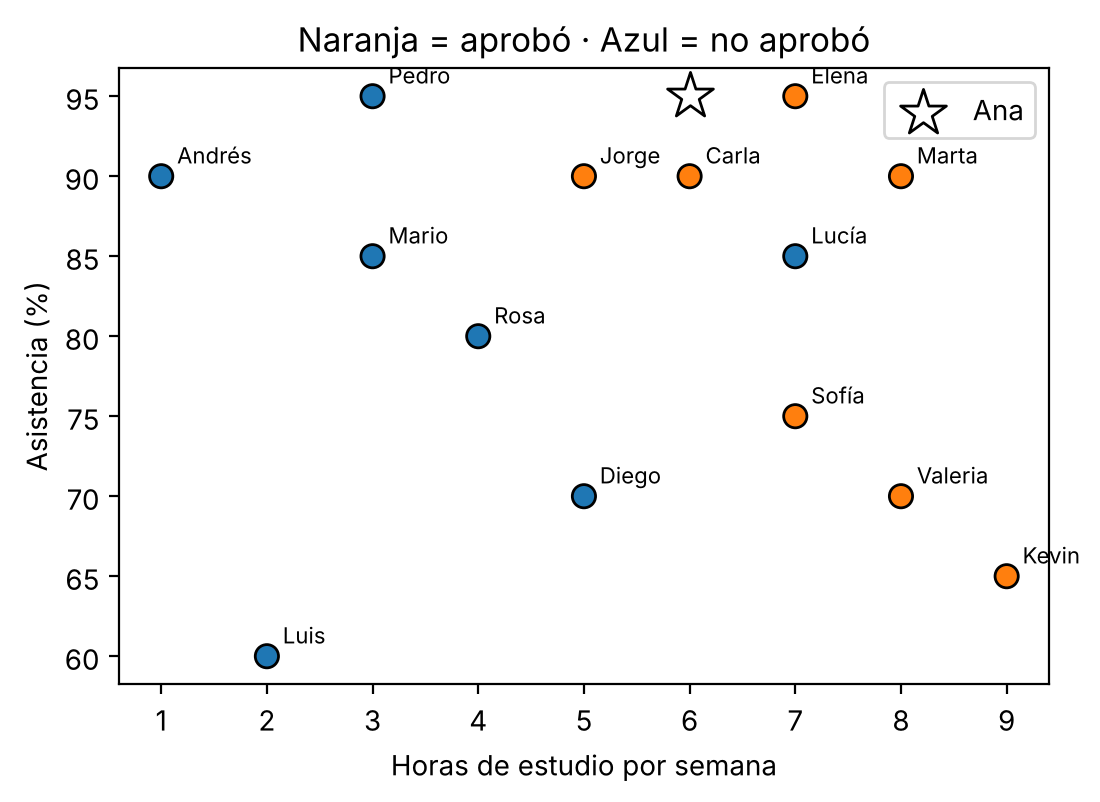

In [2]:
alumnos = pd.DataFrame({
    "nombre":     ["Luis", "Pedro", "Diego", "Carla", "Sofía", "Marta", "Jorge",
                   "Rosa", "Kevin", "Lucía", "Mario", "Elena", "Andrés", "Valeria"],
    "horas":      [2, 3, 5, 6, 7, 8, 5, 4, 9, 7, 3, 7, 1, 8],
    "asistencia": [60, 95, 70, 90, 75, 90, 90, 80, 65, 85, 85, 95, 90, 70],
    "aprobo":     [0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1],
})
ana = pd.DataFrame({"horas": [6], "asistencia": [95]})

X = alumnos[["horas", "asistencia"]]   # variables (features)
y = alumnos["aprobo"]                   # etiqueta (clase)

colores = np.where(y == 1, "tab:orange", "tab:blue")
plt.scatter(X["horas"], X["asistencia"], c=colores, s=70, edgecolor="k")
for _, f in alumnos.iterrows():
    plt.annotate(f["nombre"], (f["horas"] + 0.15, f["asistencia"] + 0.8), fontsize=8)
plt.scatter(6, 95, marker="*", s=300, c="white", edgecolor="k", label="Ana")
plt.xlabel("Horas de estudio por semana"); plt.ylabel("Asistencia (%)")
plt.title("Naranja = aprobó · Azul = no aprobó"); plt.legend()
plt.show()

Un **clasificador** es una regla que parte este plano en regiones, una por clase.

| En el ejemplo | Nombre técnico |
|---|---|
| cada alumno | observación $x_i$ |
| horas y asistencia | variables (*features*) |
| ¿aprobó? | etiqueta o clase $y_i$ |
| los 14 alumnos | datos de entrenamiento |
| tu regla | clasificador $f(x)$ |

### ✏️ Ejercicio 1 · Tu propio clasificador
Escribe la función `mi_regla(horas, asistencia)` que devuelva `1` (aprueba) o `0` (no aprueba), **inventada por ti** mirando la gráfica. La celda de revisión mide cuántos de los 14 alumnos aciertas. Intenta acertar al menos **12**.

<details><summary>💡 Pista</summary>

Por ejemplo: aprueba si `horas >= 5` **y** `asistencia >= 85`… pero entonces Sofía, Kevin y Valeria quedan mal. ¿Puedes combinar condiciones con `or`?
</details>

In [3]:
def mi_regla(horas, asistencia):
    return int(horas >= 6 or (horas >= 5 and asistencia >= 88))

In [4]:
pred_regla = [mi_regla(h, a) for h, a in zip(alumnos["horas"], alumnos["asistencia"])]
aciertos = sum(p == r for p, r in zip(pred_regla, y))
print(f"Aciertas {aciertos} de 14. Para Ana tu regla dice: {mi_regla(6, 95)}")
revisar(aciertos >= 12, "¡Buena regla!", "Intenta que tu regla acierte al menos 12.")

Aciertas 13 de 14. Para Ana tu regla dice: 1
✅ ¡Buena regla!


> Nadie llega a 14 sin hacer trampa: Lucía (7 h, 85 %) no aprobó aunque se parece a los que sí. Una regla que "memoriza" a Lucía probablemente falle con alumnos nuevos. Esa es la idea de **sobreajuste**, que veremos en la sección 6.

## 2. Entrenamiento y prueba

Lo que importa es acertar con **datos que el modelo no ha visto**. Por eso separamos:

- **Entrenamiento** (~70 %): el modelo aprende de aquí.
- **Prueba** (~30 %): apartada desde el inicio; solo se usa al final para medir.

Con 14 alumnos es muy poco para separar, así que usaremos también un conjunto más grande de 300 puntos con forma de **lunas**.

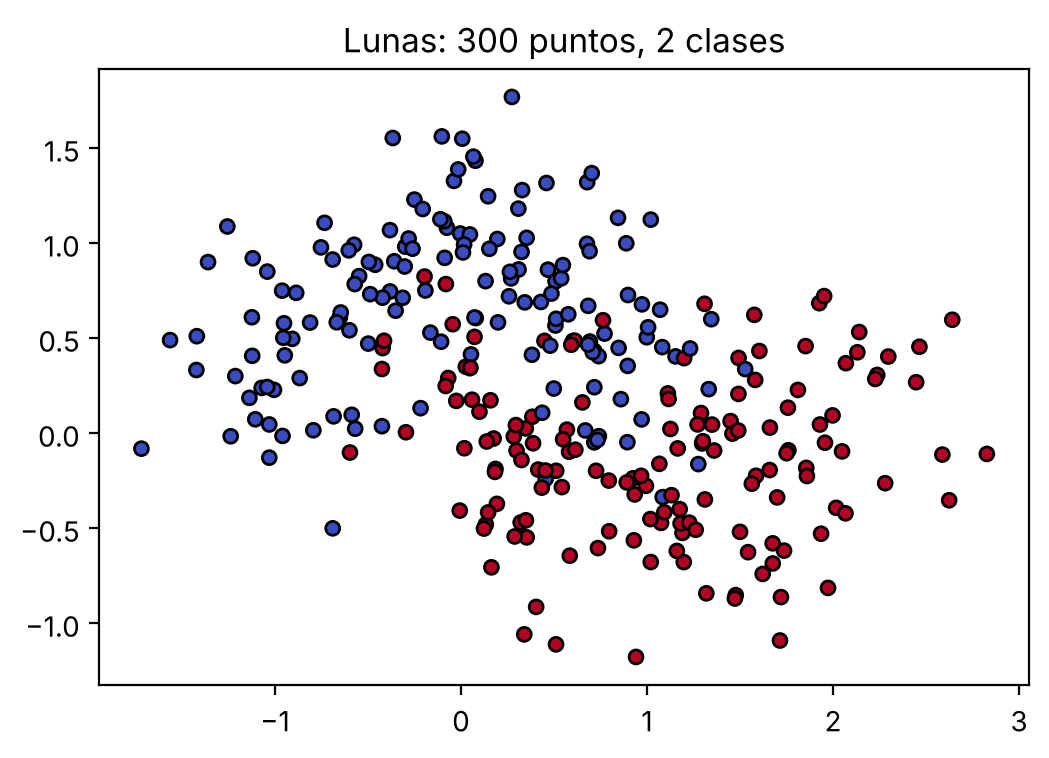

In [5]:
X_lunas, y_lunas = make_moons(n_samples=300, noise=0.3, random_state=SEMILLA)
plt.scatter(X_lunas[:, 0], X_lunas[:, 1], c=y_lunas, cmap="coolwarm", edgecolor="k", s=25)
plt.title("Lunas: 300 puntos, 2 clases")
plt.show()

### ✏️ Ejercicio 2
Separa `X_lunas`, `y_lunas` en entrenamiento y prueba con `train_test_split`: **30 %** para prueba, `random_state=SEMILLA` y `stratify=y_lunas` (mantiene la proporción de clases). Llama a los resultados `X_tr, X_te, y_tr, y_te`.

In [6]:
X_tr, X_te, y_tr, y_te = train_test_split(X_lunas, y_lunas, test_size=0.3,
                                          random_state=SEMILLA, stratify=y_lunas)
print(X_tr.shape, X_te.shape)

(210, 2) (90, 2)


In [7]:
revisar(lambda: X_tr.shape == (210, 2) and X_te.shape == (90, 2), "210 para entrenar y 90 para probar.", "test_size=0.3")

✅ 210 para entrenar y 90 para probar.


## 3. Regresión logística: sumar puntos y convertirlos en probabilidad

1. **Puntaje:** $z = w_1 \cdot \text{horas} + w_2 \cdot \text{asistencia} + b$
2. **Probabilidad** con la sigmoide: $p = \sigma(z) = \dfrac{1}{1 + e^{-z}}$
3. **Decisión:** si $p \ge 0.5$ → "aprueba".

### ✏️ Ejercicio 3 · La sigmoide y el puntaje de Ana
1. Escribe `sigmoide(z)` (usa `np.exp`).
2. Con los pesos de ejemplo $w_1 = 1.2$, $w_2 = 0.1$, $b = -15$, calcula `z_ana` y `p_ana`.

In [8]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

w1, w2, b = 1.2, 0.1, -15
z_ana = w1 * 6 + w2 * 95 + b
p_ana = sigmoide(z_ana)
print(f"z = {z_ana:.2f}, p = {p_ana:.3f}")

z = 1.70, p = 0.846


✅ La sigmoide funciona: σ(0) = 0.5.
✅ Ana: z = 1.7 → p ≈ 0.85.


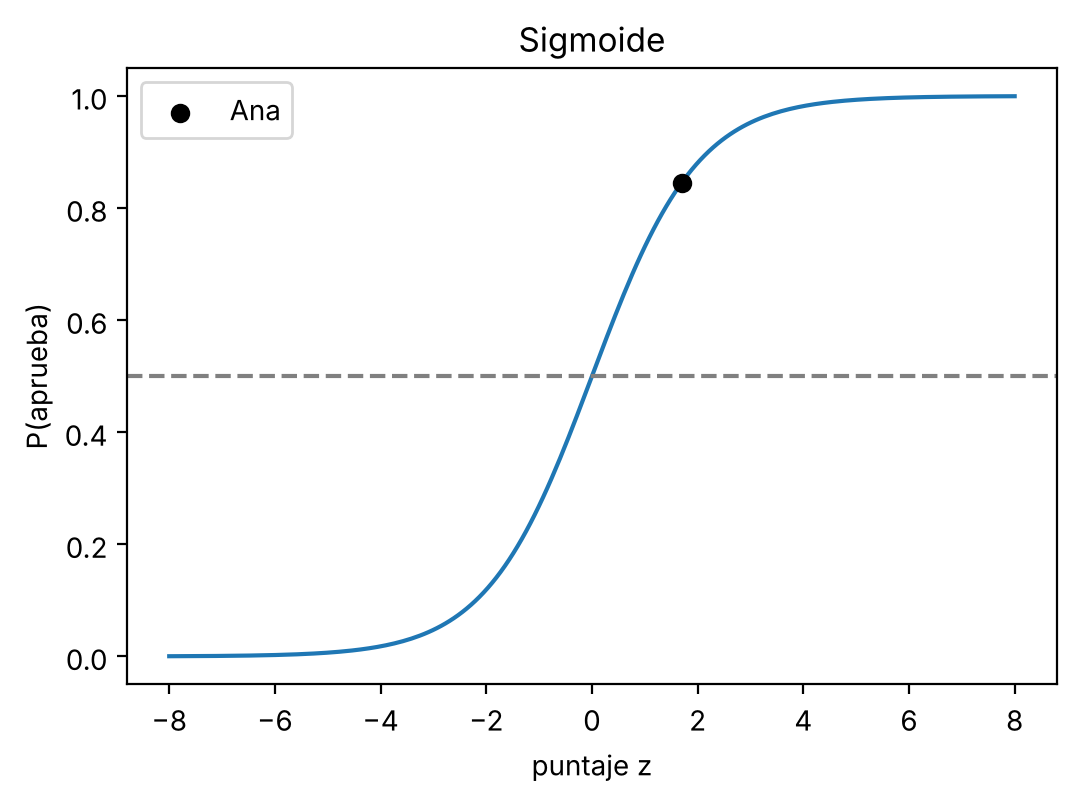

In [9]:
revisar(lambda: abs(sigmoide(0) - 0.5) < 1e-9 and sigmoide(10) > 0.99, "La sigmoide funciona: σ(0) = 0.5.", "σ(z) = 1 / (1 + np.exp(-z))")
revisar(lambda: abs(z_ana - 1.7) < 1e-9 and abs(p_ana - 0.8455) < 1e-3, "Ana: z = 1.7 → p ≈ 0.85.", "z = 1.2·6 + 0.1·95 − 15")

zz = np.linspace(-8, 8, 200)
plt.plot(zz, 1 / (1 + np.exp(-zz))); plt.axhline(0.5, ls="--", c="gray")
plt.scatter([1.7], [1 / (1 + np.exp(-1.7))], c="k", zorder=3, label="Ana")
plt.xlabel("puntaje z"); plt.ylabel("P(aprueba)"); plt.legend(); plt.title("Sigmoide")
plt.show()

### Aprender los pesos: descenso por gradiente

Se buscan los pesos con menor **pérdida logarítmica** $\mathcal{L} = -\frac{1}{n}\sum_i \big[y_i \log p_i + (1-y_i)\log(1-p_i)\big]$. En cada paso:

$$w_j \leftarrow w_j - \eta \cdot \frac{1}{n}\sum_i (p_i - y_i)\, x_{ij}$$

Primero **escalamos** las variables (media 0, desviación 1) para que horas y asistencia pesen parecido.

### ✏️ Ejercicio 4 · Entrena tú la regresión logística
Completa el ciclo: calcula `p` con la sigmoide, el `error = p - y` y actualiza `w` y `b`. Corre 2000 pasos con `eta = 0.5`.

pesos: [3.22 1.11] b: -0.45 pérdida final: 0.292
P(Ana aprueba) = 0.85


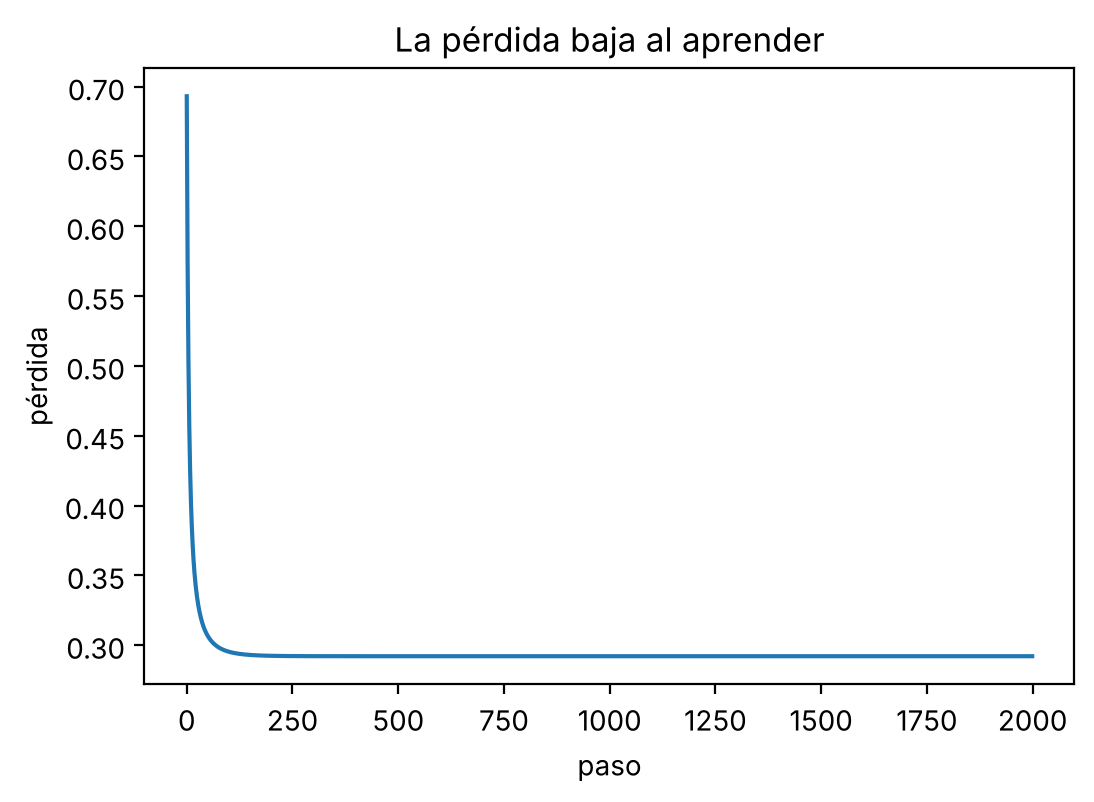

In [10]:
escalador = StandardScaler().fit(X)
Xe = escalador.transform(X)
ye = y.to_numpy()

w = np.zeros(2); b = 0.0; eta = 0.5
historia = []
for paso in range(2000):
    p = sigmoide(Xe @ w + b)
    error = p - ye
    w = w - eta * (Xe.T @ error) / len(ye)
    b = b - eta * error.mean()
    historia.append(-np.mean(ye * np.log(p + 1e-12) + (1 - ye) * np.log(1 - p + 1e-12)))

p_ana_aprendida = sigmoide(escalador.transform(ana) @ w + b)[0]
print("pesos:", w.round(2), "b:", round(b, 2), "pérdida final:", round(historia[-1], 3))
print(f"P(Ana aprueba) = {p_ana_aprendida:.2f}")
plt.plot(historia); plt.xlabel("paso"); plt.ylabel("pérdida"); plt.title("La pérdida baja al aprender"); plt.show()

In [11]:
sk = LogisticRegression(C=1e6).fit(Xe, ye)
print("scikit-learn:", sk.coef_.round(2), sk.intercept_.round(2))
revisar(lambda: historia[-1] < historia[0] - 0.2 and p_ana_aprendida > 0.8,
        f"La pérdida bajó y Ana tiene P ≈ {p_ana_aprendida:.2f} de aprobar.", "Revisa la fórmula de actualización.")

scikit-learn: [[3.22 1.11]] [-0.45]
✅ La pérdida bajó y Ana tiene P ≈ 0.85 de aprobar.


**Interpretar los pesos.** $\log\frac{p}{1-p} = z$: cada unidad extra de una variable **multiplica los momios** (*odds*) por $e^{w}$. Con la variable escalada, "una unidad" es una desviación estándar.

Ahora la versión de una línea con scikit-learn, en las lunas:

Exactitud en prueba: 0.83


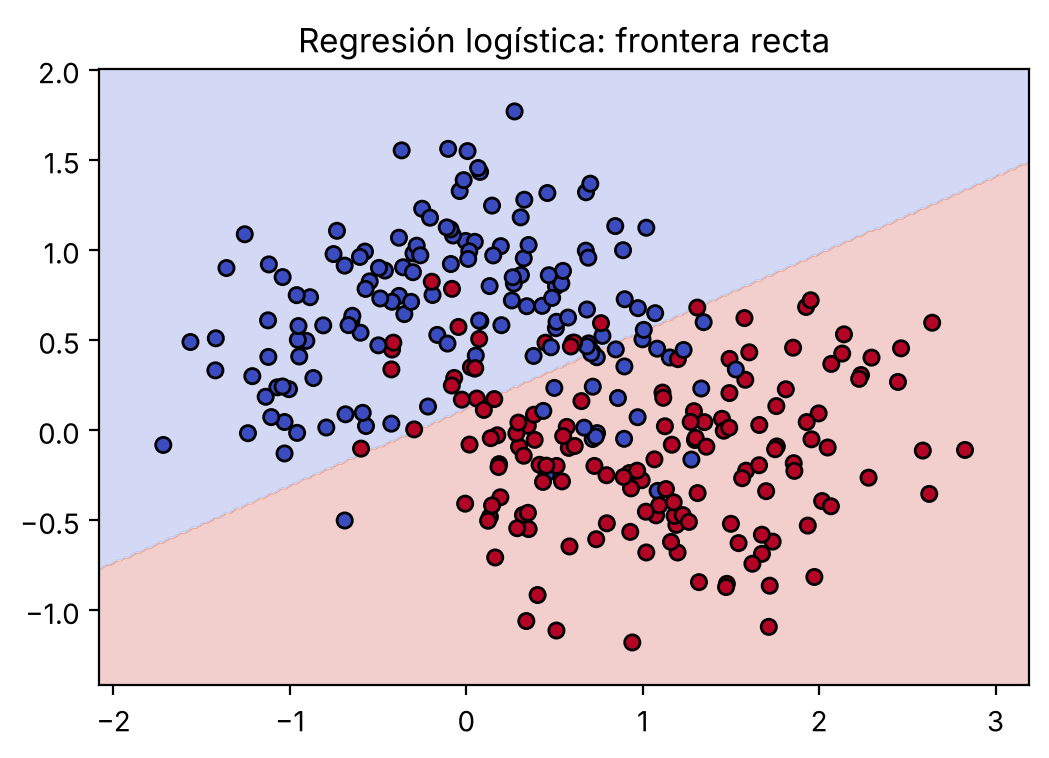

In [12]:
logreg = LogisticRegression().fit(X_tr, y_tr)
print(f"Exactitud en prueba: {logreg.score(X_te, y_te):.2f}")
dibujar_frontera(logreg, X_lunas, y_lunas, "Regresión logística: frontera recta")
plt.show()

## 4. k vecinos más cercanos (kNN): "dime con quién andas"

kNN **no aprende ninguna regla**: guarda a todos los alumnos y, cuando llega alguien nuevo,

1. mide la **distancia** a cada alumno: $d = \sqrt{(\Delta\text{horas})^2 + (\Delta\text{asistencia})^2}$,
2. ordena de más cerca a más lejos,
3. toma los **k** más cercanos,
4. **votan**: gana la mayoría.

### ✏️ Ejercicio 5 · kNN a mano
1. Agrega a `alumnos` la columna `"dist"`: la distancia de cada alumno a Ana (6 h, 95 %).
2. Guarda en `vecinos3` las 3 filas más cercanas (`sort_values` + `head`).
3. Guarda en `voto` la predicción: `1` si la mayoría de esos 3 aprobó.

In [13]:
alumnos["dist"] = np.sqrt((alumnos["horas"] - 6) ** 2 + (alumnos["asistencia"] - 95) ** 2)
vecinos3 = alumnos.sort_values("dist").head(3)
voto = int(vecinos3["aprobo"].sum() >= 2)
vecinos3

,nombre,horas,asistencia,aprobo,dist
11,Elena,7,95,1,1.0
1,Pedro,3,95,0,3.0
3,Carla,6,90,1,5.0


In [14]:
revisar(lambda: list(vecinos3["nombre"]) == ["Elena", "Pedro", "Carla"], "Vecinos: Elena (1), Pedro (3) y Carla (5.1).", "Usa np.sqrt de la suma de los cuadrados.")
revisar(lambda: voto == 1, "2 de 3 aprobaron → kNN dice que Ana aprueba.", "Suma la columna aprobo de los vecinos.")

✅ Vecinos: Elena (1), Pedro (3) y Carla (5.1).
✅ 2 de 3 aprobaron → kNN dice que Ana aprueba.


🤔 ¿Pedro (3 h, 95 %) más parecido a Ana que Carla (6 h, 90 %)? Pedro no aprobó y Carla sí. Pasa porque la asistencia va de 60 a 95 y las horas de 1 a 9: **sin escalar, la asistencia domina la distancia**.

### ✏️ Ejercicio 6 · Escala y repite
Usa `Xe` (las variables escaladas de la sección 3) y `escalador.transform(ana)` para calcular `dist_esc`, la distancia escalada de cada alumno a Ana. Guarda en `vecinos3_esc` los **nombres** de los 3 más cercanos.

In [15]:
ana_e = escalador.transform(ana)[0]
dist_esc = np.sqrt(((Xe - ana_e) ** 2).sum(axis=1))
vecinos3_esc = list(alumnos["nombre"].iloc[np.argsort(dist_esc)[:3]])
print(vecinos3_esc)

['Elena', 'Carla', 'Jorge']


In [16]:
revisar(lambda: "Pedro" not in vecinos3_esc and "Carla" in vecinos3_esc, lambda: f"Escalado, Pedro ya no es vecino: {vecinos3_esc}", "Resta ana_e a cada fila de Xe, eleva al cuadrado y suma por fila.")

✅ Escalado, Pedro ya no es vecino: ['Elena', 'Carla', 'Jorge']


### ¿Qué tan grande debe ser k?
- $k = 1$: copia al vecino más cercano, aunque sea una excepción.
- $k$ muy grande: vota casi todo el salón.

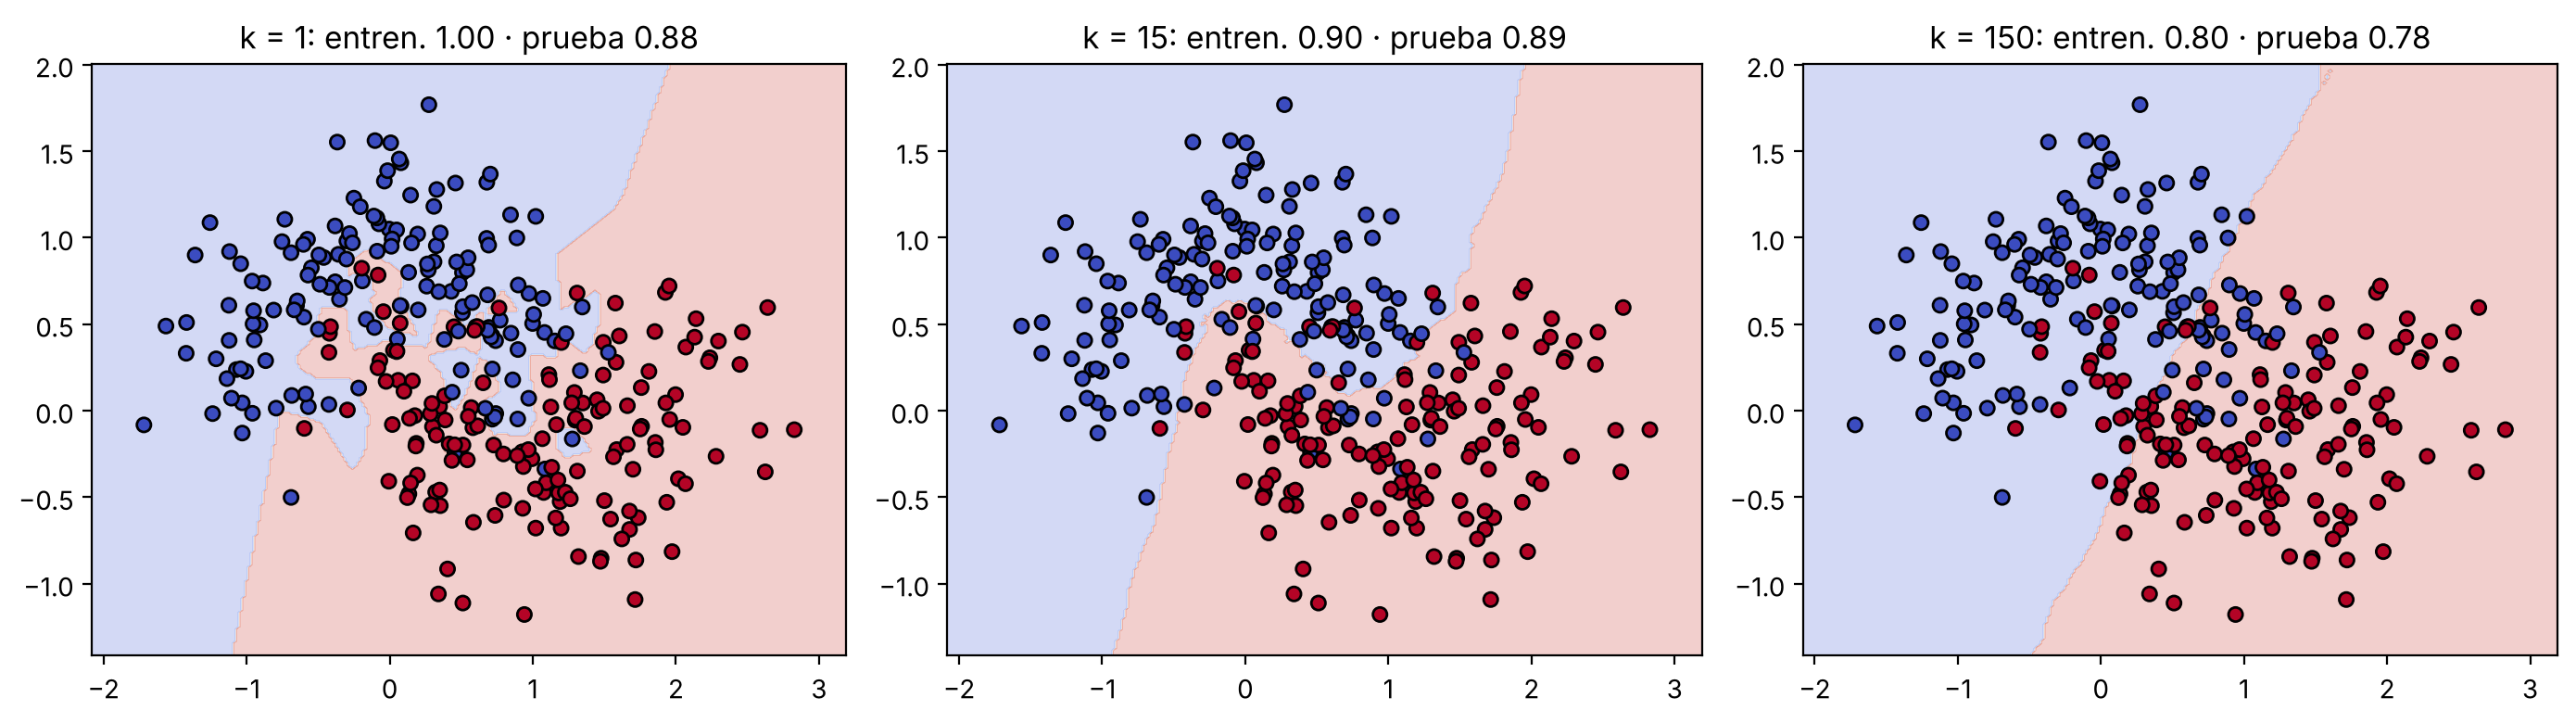

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, k in zip(axs, [1, 15, 150]):
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    dibujar_frontera(knn, X_lunas, y_lunas, f"k = {k}: entren. {knn.score(X_tr, y_tr):.2f} · prueba {knn.score(X_te, y_te):.2f}", ax)
plt.tight_layout(); plt.show()

### ✏️ Ejercicio 7 · Elige k con validación cruzada
Para cada `k` en `range(1, 60, 2)`, calcula la exactitud media con `cross_val_score(modelo, X_tr, y_tr, cv=5).mean()`. Guarda los resultados en la lista `puntajes` y el mejor k en `mejor_k`.

> Usamos **solo el entrenamiento** para elegir k. Si eliges mirando la prueba, tu estimación del error queda sesgada.

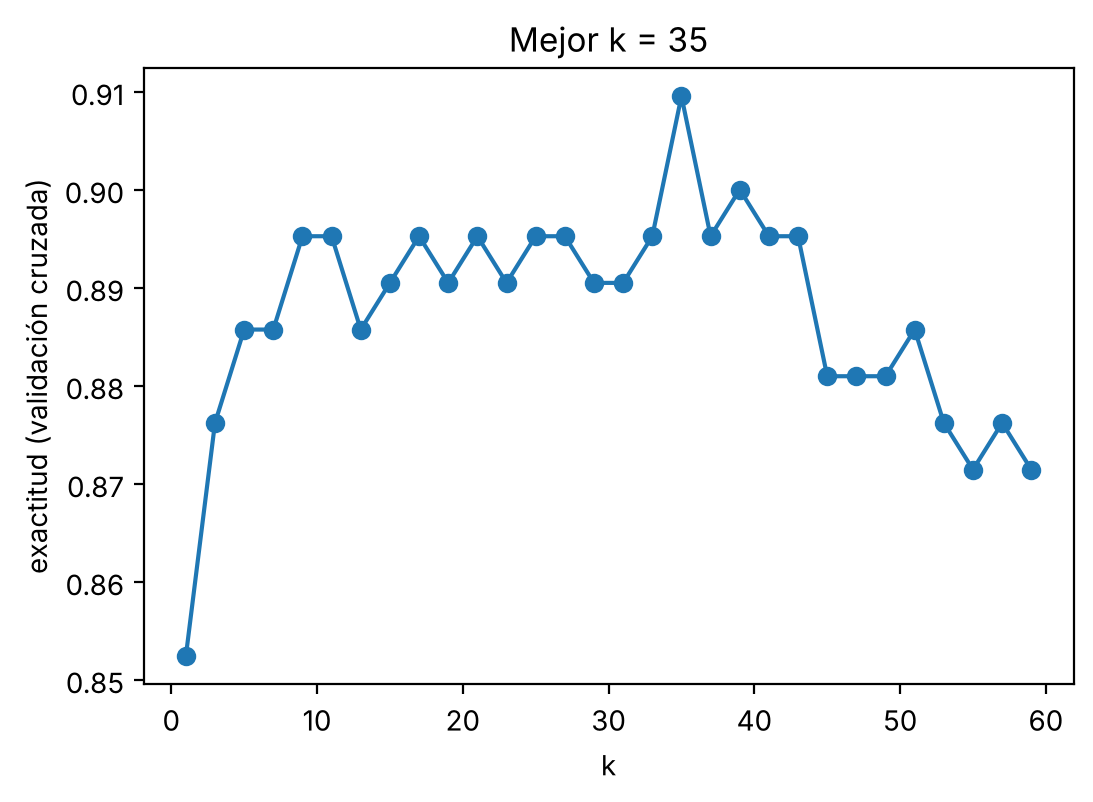

In [18]:
ks = list(range(1, 60, 2))
puntajes = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_tr, y_tr, cv=5).mean() for k in ks]
mejor_k = ks[int(np.argmax(puntajes))]
plt.plot(ks, puntajes, marker="o"); plt.xlabel("k"); plt.ylabel("exactitud (validación cruzada)")
plt.title(f"Mejor k = {mejor_k}"); plt.show()

In [19]:
revisar(lambda: len(puntajes) == 30 and mejor_k > 1, lambda: f"Mejor k = {mejor_k}: ni 1 ni enorme.", "Un puntaje por cada k; mejor_k = ks[np.argmax(puntajes)].")

✅ Mejor k = 35: ni 1 ni enorme.


## 5. Árboles de decisión: un juego de preguntas

Como en **"Adivina quién"**: cada pregunta de sí o no separa a los alumnos en dos grupos. El árbol elige la pregunta que deja los grupos más **puros**, medido con el **índice de Gini**:

$$\text{Gini} = 1 - \sum_k p_k^2$$

Un grupo puro (todos aprobaron, o ninguno) tiene Gini = 0; mitad y mitad tiene Gini = 0.5. Para un corte se usa el Gini **ponderado** por el tamaño de cada lado.

### ✏️ Ejercicio 8 · ¿Dónde cortar?
1. Escribe `gini(etiquetas)` para una lista de 0 y 1.
2. Para cada umbral en `[1.5, 2.5, …, 8.5]`, separa a los alumnos en `horas <= umbral` y `horas > umbral`, y calcula el Gini ponderado. Guarda el mejor en `mejor_umbral`.

In [20]:
def gini(etiquetas):
    etiquetas = np.asarray(etiquetas)
    if len(etiquetas) == 0:
        return 0.0
    p1 = etiquetas.mean()
    return 1 - (p1 ** 2 + (1 - p1) ** 2)

resultados = {}
for u in np.arange(1.5, 9, 1.0):
    izq = y[alumnos["horas"] <= u]
    der = y[alumnos["horas"] > u]
    resultados[u] = (len(izq) * gini(izq) + len(der) * gini(der)) / len(y)
mejor_umbral = min(resultados, key=resultados.get)
pd.Series(resultados).round(3)

1.5    0.462
2.5    0.417
3.5    0.300
4.5    0.222
5.5    0.245
6.5    0.333
7.5    0.364
8.5    0.462
dtype: float64

In [21]:
revisar(lambda: gini([1, 1, 1]) == 0 and abs(gini([0, 1]) - 0.5) < 1e-9, "Gini correcto.", "Gini = 1 − (p1² + p0²)")
revisar(lambda: mejor_umbral == 4.5, "El mejor primer corte es horas ≤ 4.5, igual que en las diapositivas.", "Busca el umbral con menor Gini ponderado.")

✅ Gini correcto.
✅ El mejor primer corte es horas ≤ 4.5, igual que en las diapositivas.


Ahora dejemos que scikit-learn construya el árbol completo (profundidad 2) y veamos qué decide para Ana:

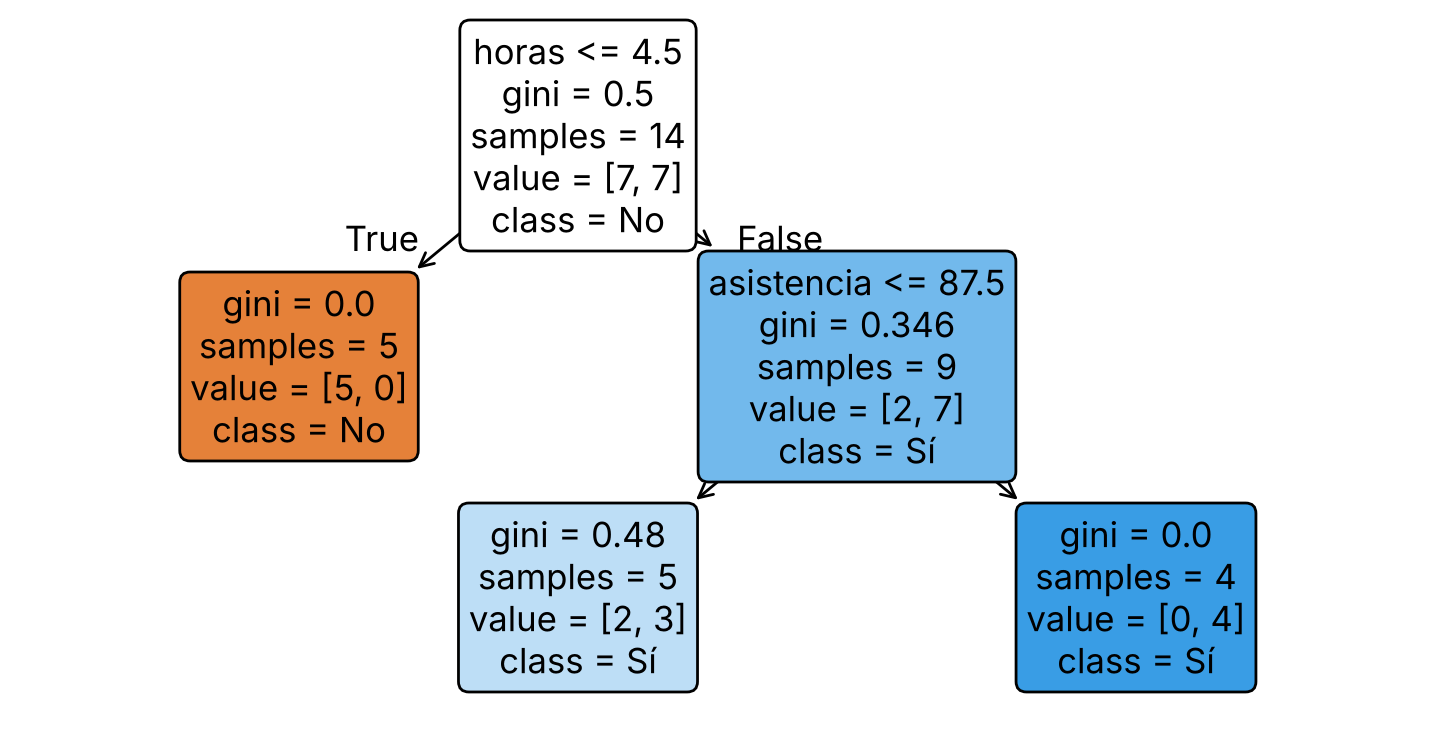

Predicción para Ana: aprueba


In [22]:
arbol = DecisionTreeClassifier(max_depth=2, random_state=SEMILLA).fit(X, y)
plt.figure(figsize=(9, 4.5))
plot_tree(arbol, feature_names=["horas", "asistencia"], class_names=["No", "Sí"], filled=True, rounded=True)
plt.show()
print("Predicción para Ana:", "aprueba" if arbol.predict(ana)[0] == 1 else "no aprueba")

### ✏️ Ejercicio 9 · Profundidad y sobreajuste
En las lunas, entrena árboles con `max_depth` de 1 a 15. Guarda en las listas `exact_tr` y `exact_te` la exactitud en entrenamiento y en prueba. Grafica ambas curvas.

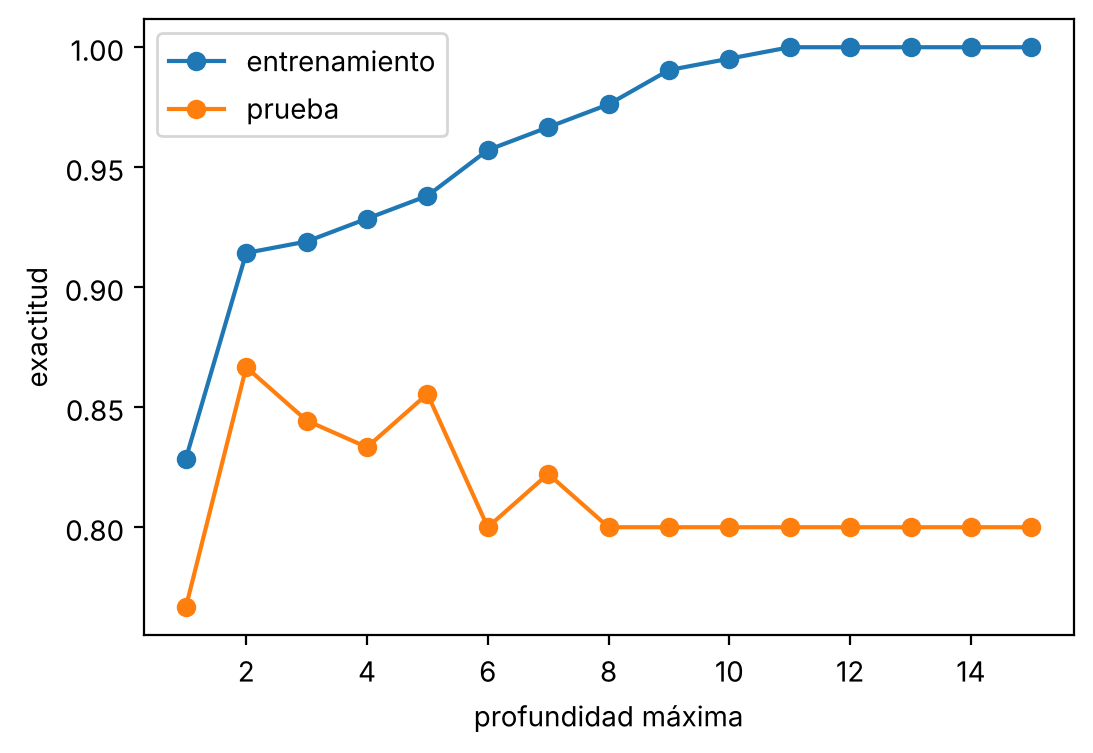

In [23]:
profs = range(1, 16)
exact_tr, exact_te = [], []
for d in profs:
    a = DecisionTreeClassifier(max_depth=d, random_state=SEMILLA).fit(X_tr, y_tr)
    exact_tr.append(a.score(X_tr, y_tr)); exact_te.append(a.score(X_te, y_te))
plt.plot(profs, exact_tr, marker="o", label="entrenamiento")
plt.plot(profs, exact_te, marker="o", label="prueba")
plt.xlabel("profundidad máxima"); plt.ylabel("exactitud"); plt.legend(); plt.show()

In [24]:
revisar(lambda: len(exact_tr) == 15 and exact_tr[-1] > 0.98 and exact_te[-1] < exact_tr[-1] - 0.05,
        "Con mucha profundidad el árbol memoriza: ~100 % en entrenamiento pero peor en prueba.", "Un árbol por profundidad; guarda score de train y de test.")

✅ Con mucha profundidad el árbol memoriza: ~100 % en entrenamiento pero peor en prueba.


## 6. Sesgo y varianza

Imagina entrenar el **mismo algoritmo muchas veces**, cada una con una muestra distinta de datos:

- **Sesgo**: qué tan lejos de la respuesta correcta cae el **promedio** de las predicciones (modelo demasiado simple → **subajuste**).
- **Varianza**: qué tan **dispersas** quedan las predicciones entre muestras (modelo que cambia mucho → **sobreajuste**).

$$\mathbb{E}\big[(y - \hat f(x))^2\big] = \text{sesgo}^2 + \text{varianza} + \text{ruido}$$

Vamos a verlo: 12 muestras distintas, 12 árboles.

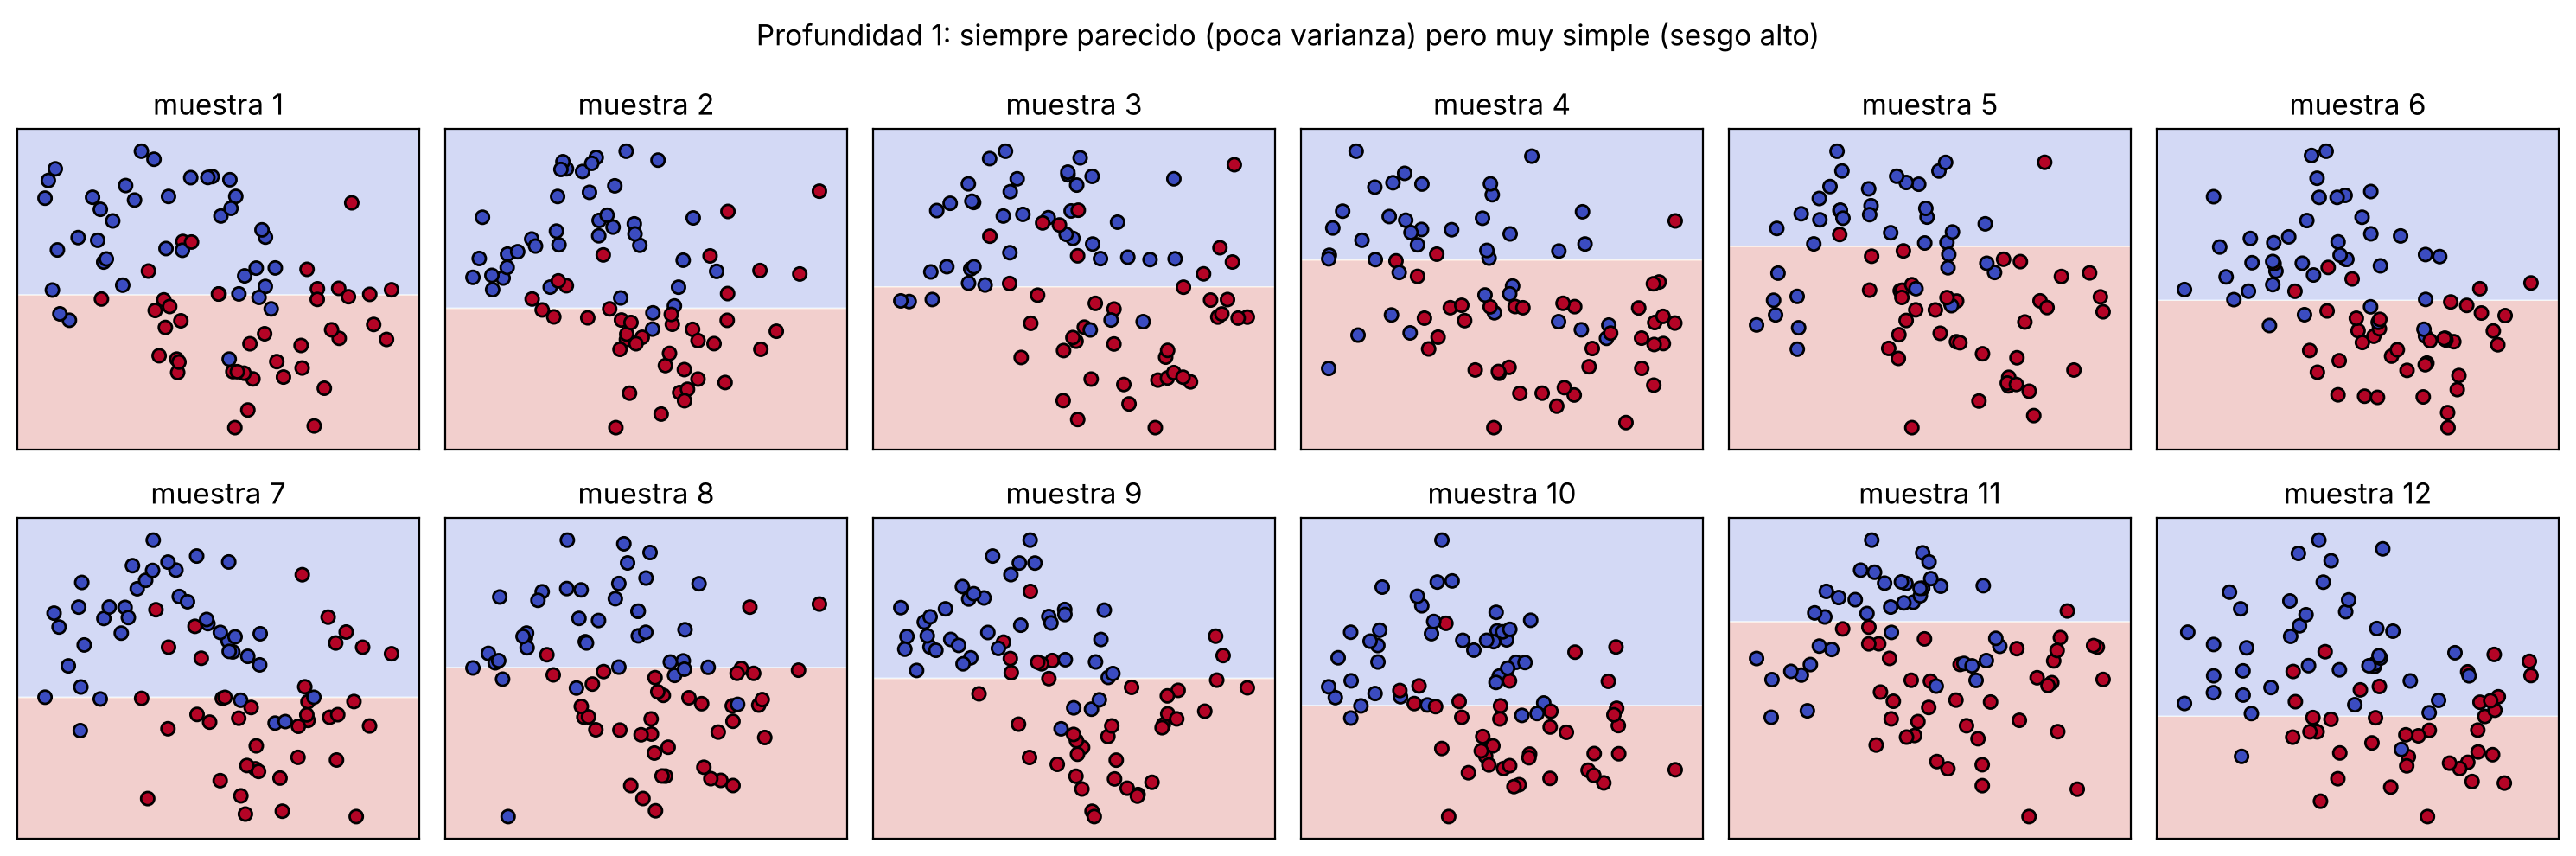

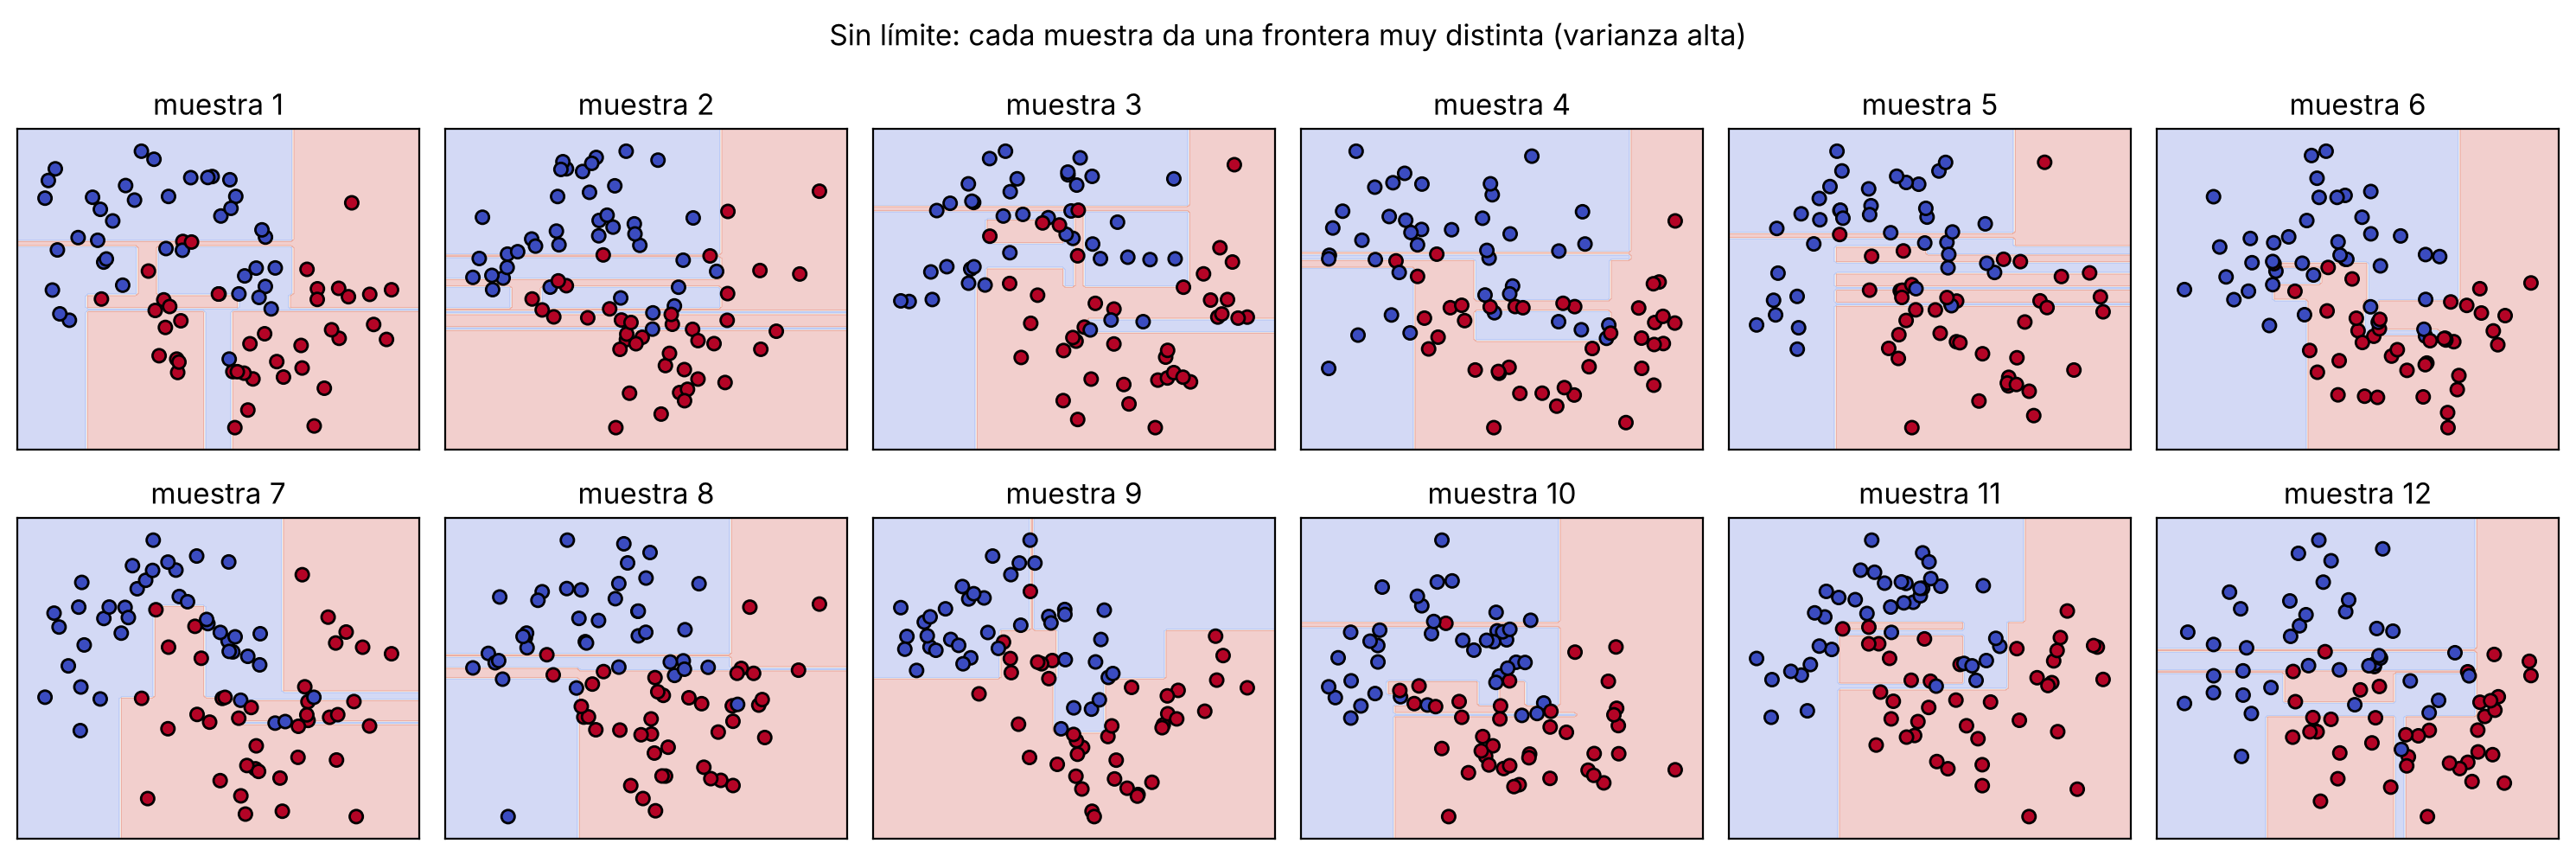

In [25]:
def doce_modelos(crear_modelo, titulo):
    fig, axs = plt.subplots(2, 6, figsize=(15, 5))
    for i, ax in enumerate(axs.ravel()):
        Xm, ym = make_moons(n_samples=80, noise=0.3, random_state=100 + i)
        dibujar_frontera(crear_modelo().fit(Xm, ym), Xm, ym, f"muestra {i+1}", ax, n=120)
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(titulo); plt.tight_layout(); plt.show()

doce_modelos(lambda: DecisionTreeClassifier(max_depth=1), "Profundidad 1: siempre parecido (poca varianza) pero muy simple (sesgo alto)")
doce_modelos(lambda: DecisionTreeClassifier(), "Sin límite: cada muestra da una frontera muy distinta (varianza alta)")

### ✏️ Ejercicio 10 · Mide la varianza en un punto
Para 50 muestras distintas (`random_state=100 + i`), entrena un modelo y anota su predicción de **probabilidad** (`predict_proba(...)[0, 1]`) en el punto `x0 = [[0.5, 0.25]]`. Hazlo para un árbol de profundidad 1 y para un árbol sin límite, y guarda la **desviación estándar** de las 50 predicciones en `var_simple` y `var_complejo`.

In [26]:
x0 = [[0.5, 0.25]]
def predicciones(crear_modelo, veces=50):
    out = []
    for i in range(veces):
        Xm, ym = make_moons(n_samples=80, noise=0.3, random_state=100 + i)
        out.append(crear_modelo().fit(Xm, ym).predict_proba(x0)[0, 1])
    return np.array(out)

var_simple = predicciones(lambda: DecisionTreeClassifier(max_depth=1)).std()
var_complejo = predicciones(lambda: DecisionTreeClassifier()).std()
print(f"desv. estándar · simple: {var_simple:.2f} · complejo: {var_complejo:.2f}")

desv. estándar · simple: 0.27 · complejo: 0.50


In [27]:
revisar(lambda: var_complejo > var_simple, "El árbol sin límite cambia mucho más de muestra a muestra: varianza alta.", "Entrena 50 veces cada modelo y usa .std().")

✅ El árbol sin límite cambia mucho más de muestra a muestra: varianza alta.


| Algoritmo | más simple (sesgo) ← → más complejo (varianza) |
|---|---|
| Regresión logística | regularización fuerte (C chico) ← → sin regularizar |
| kNN | k grande ← → k = 1 |
| Árbol | poca profundidad ← → sin límite |
| SVM | C y γ chicos ← → grandes |

**Diagnóstico rápido:** malo en entrenamiento y prueba → sesgo; muy bueno en entrenamiento y malo en prueba → varianza.

## 7. Random Forest: la sabiduría de la multitud

Muchos árboles **distintos** (cada uno ve una muestra al azar de los datos y de las variables) **votan**. Los errores de cada árbol se compensan: se reduce la varianza sin aumentar mucho el sesgo.

### ✏️ Ejercicio 11
1. Entrena un `RandomForestClassifier(n_estimators=200, random_state=SEMILLA)` en las lunas y guarda su exactitud en prueba en `exact_bosque`.
2. Compárala con la de un solo árbol sin límite (`exact_arbol`).

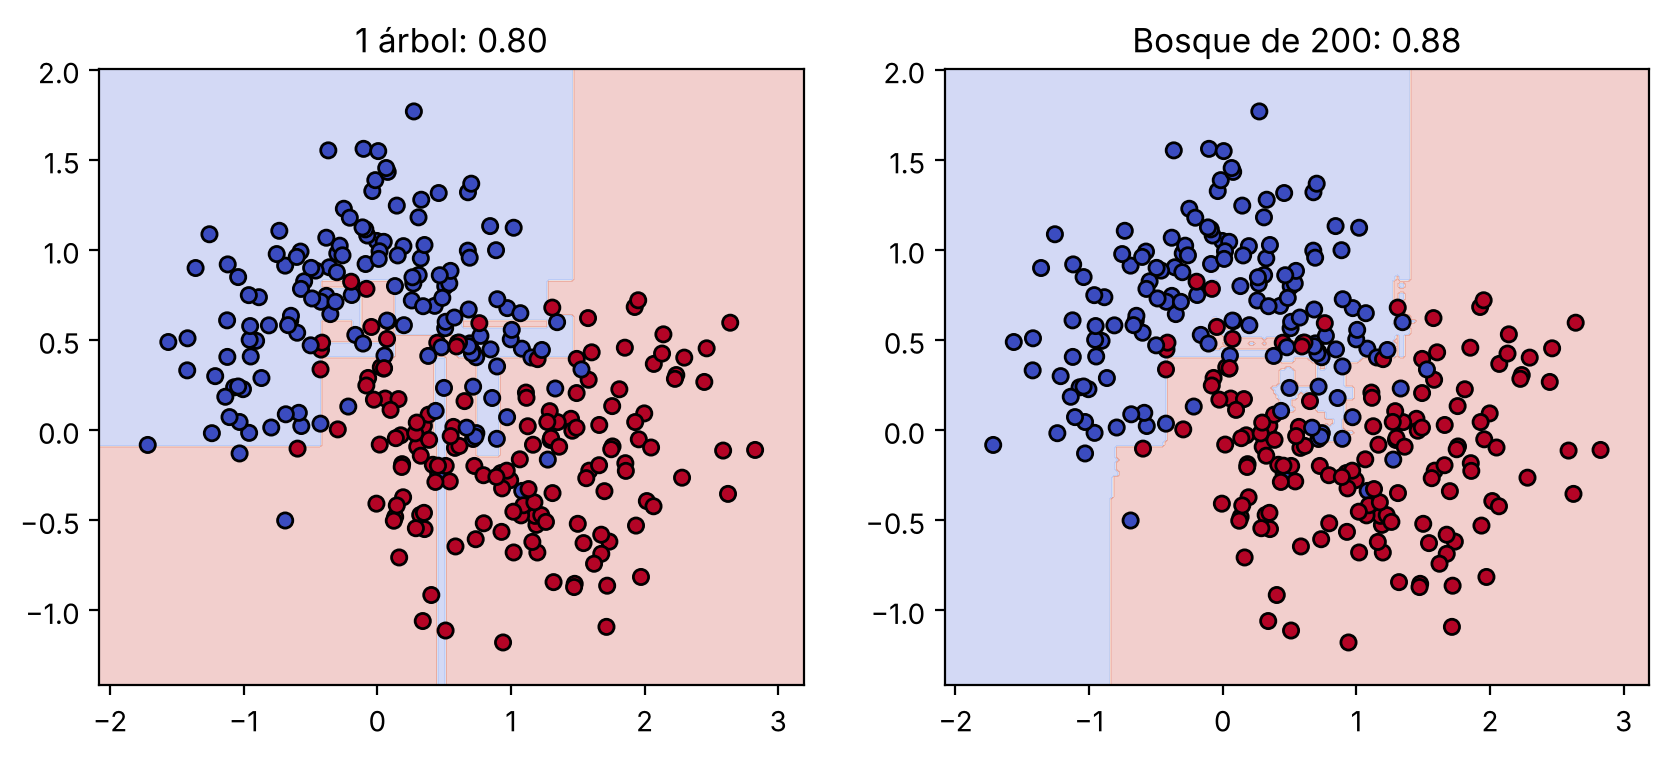

In [28]:
bosque = RandomForestClassifier(n_estimators=200, random_state=SEMILLA).fit(X_tr, y_tr)
arbol_solo = DecisionTreeClassifier(random_state=SEMILLA).fit(X_tr, y_tr)
exact_bosque, exact_arbol = bosque.score(X_te, y_te), arbol_solo.score(X_te, y_te)
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
dibujar_frontera(arbol_solo, X_lunas, y_lunas, f"1 árbol: {exact_arbol:.2f}", axs[0])
dibujar_frontera(bosque, X_lunas, y_lunas, f"Bosque de 200: {exact_bosque:.2f}", axs[1])
plt.show()

In [29]:
revisar(lambda: exact_bosque >= exact_arbol, lambda: f"El bosque ({exact_bosque:.2f}) supera o iguala al árbol ({exact_arbol:.2f}).", "Entrena ambos con X_tr y mide con X_te.")

✅ El bosque (0.88) supera o iguala al árbol (0.80).


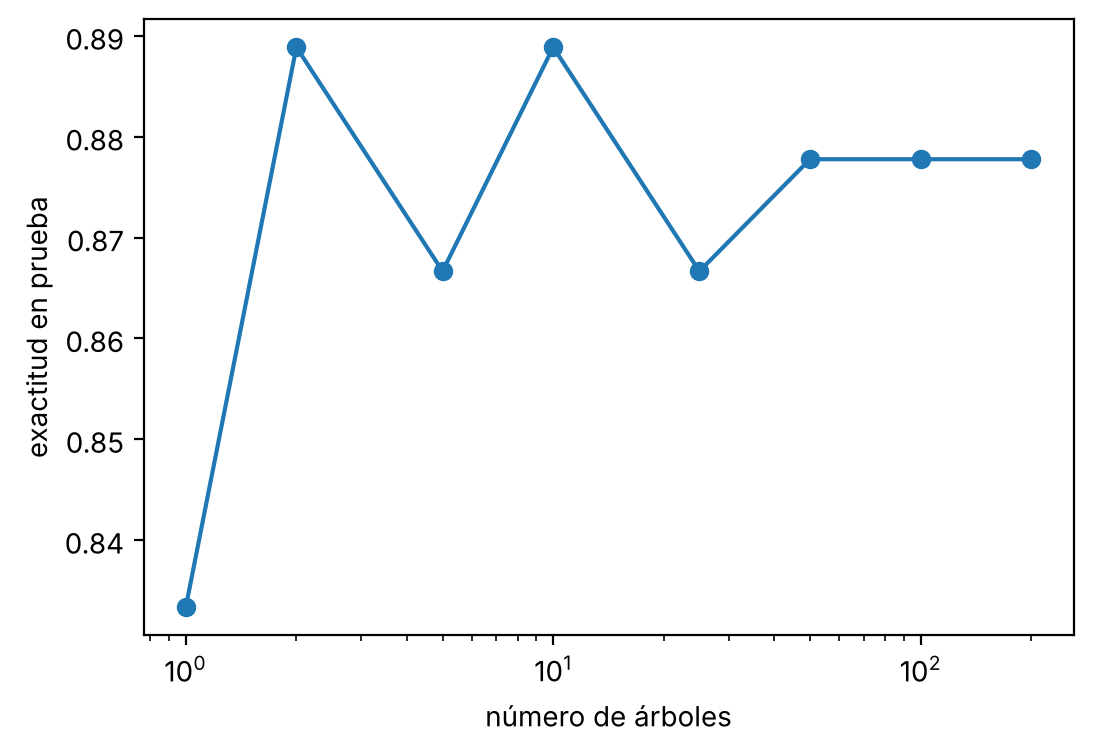

In [30]:
# ¿Cuántos árboles hacen falta?
ns = [1, 2, 5, 10, 25, 50, 100, 200]
plt.plot(ns, [RandomForestClassifier(n_estimators=n, random_state=SEMILLA).fit(X_tr, y_tr).score(X_te, y_te) for n in ns], marker="o")
plt.xscale("log"); plt.xlabel("número de árboles"); plt.ylabel("exactitud en prueba"); plt.show()

## 8. SVM: la calle más ancha

La SVM busca la frontera que deja la **mayor distancia posible** (el **margen**) entre las dos clases. Los puntos que tocan la orilla de la calle son los **vectores de soporte**: solo ellos definen la frontera.

- **C** controla cuánto se castigan los puntos del lado equivocado (C chico = calle ancha y tolerante).
- Con un **kernel** (`"rbf"`) la frontera puede curvarse.

Vectores de soporte: ['Pedro', 'Diego', 'Rosa', 'Lucía', 'Carla', 'Sofía', 'Jorge', 'Valeria']
Ana: aprueba


/usr/local/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


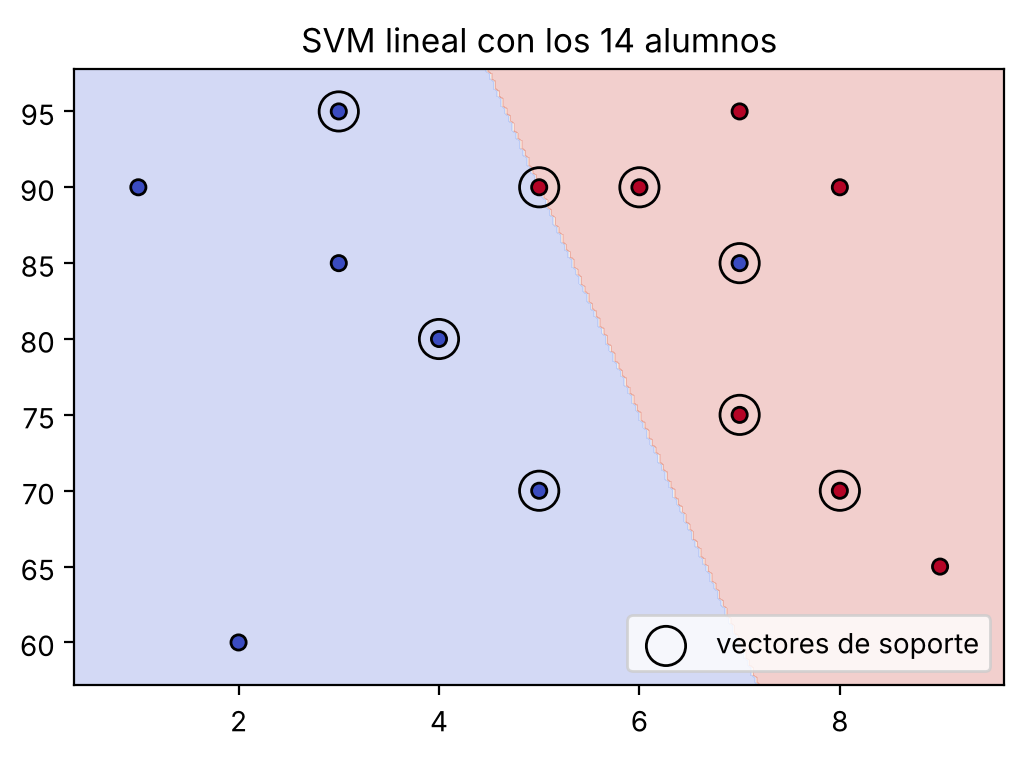

In [31]:
svm_lin = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1)).fit(X, y)
sv = svm_lin[-1].support_
print("Vectores de soporte:", list(alumnos["nombre"].iloc[sv]))
print("Ana:", "aprueba" if svm_lin.predict(ana)[0] else "no aprueba")
dibujar_frontera(svm_lin, X.to_numpy(), y.to_numpy(), "SVM lineal con los 14 alumnos")
plt.scatter(X.iloc[sv, 0], X.iloc[sv, 1], s=200, facecolors="none", edgecolors="k", label="vectores de soporte")
plt.legend(); plt.show()

### ✏️ Ejercicio 12 · Kernel y C en círculos
Los círculos no se pueden separar con una recta. Entrena en `X_c, y_c`:

1. `svm_lineal`: `SVC(kernel="linear")`
2. `svm_rbf`: `SVC(kernel="rbf", C=1)`

y guarda sus exactitudes en prueba en `ex_lineal` y `ex_rbf`.

In [32]:
X_c, y_c = make_circles(n_samples=300, noise=0.12, factor=0.45, random_state=SEMILLA)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X_c, y_c, test_size=0.3, random_state=SEMILLA)

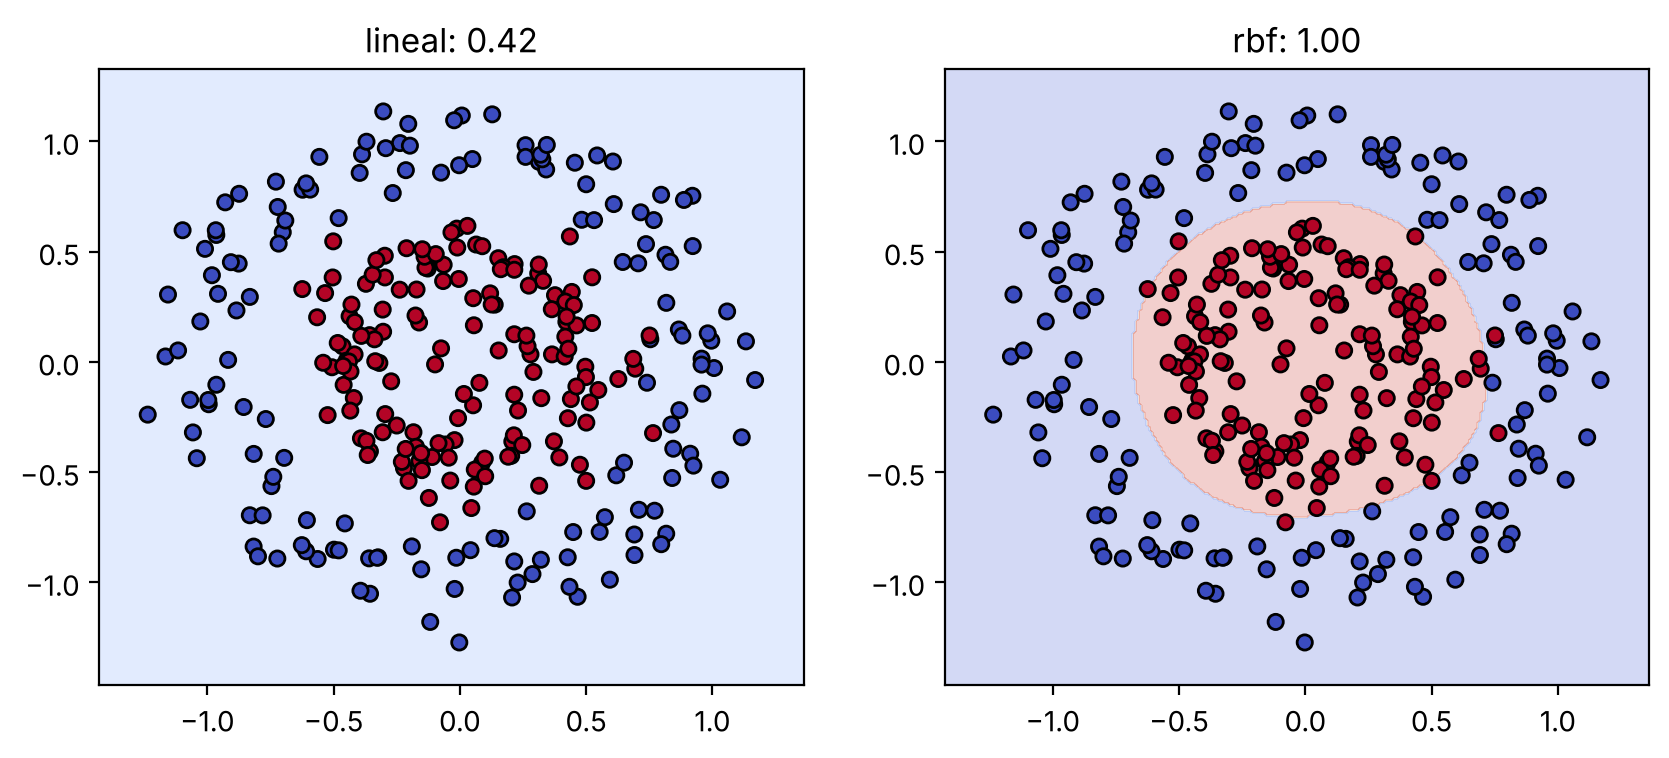

In [33]:
svm_lineal = SVC(kernel="linear").fit(Xc_tr, yc_tr)
svm_rbf = SVC(kernel="rbf", C=1).fit(Xc_tr, yc_tr)
ex_lineal, ex_rbf = svm_lineal.score(Xc_te, yc_te), svm_rbf.score(Xc_te, yc_te)
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
dibujar_frontera(svm_lineal, X_c, y_c, f"lineal: {ex_lineal:.2f}", axs[0])
dibujar_frontera(svm_rbf, X_c, y_c, f"rbf: {ex_rbf:.2f}", axs[1])
plt.show()

In [34]:
revisar(lambda: ex_rbf > 0.9 and ex_lineal < 0.7, "La recta no puede; el kernel rbf sí.", 'Prueba SVC(kernel="linear") y SVC(kernel="rbf").')

✅ La recta no puede; el kernel rbf sí.


## 9. Naive Bayes: el detective

Junta **pistas por separado** y calcula qué es más probable, suponiendo que las pistas son independientes dada la clase ("ingenuo"):

$$P(\text{sí} \mid \text{pistas}) \propto P(\text{sí}) \cdot P(\text{pista}_1 \mid \text{sí}) \cdot P(\text{pista}_2 \mid \text{sí})$$

Pistas sobre Ana: **estudia mucho** (horas ≥ 6) y **asiste mucho** (asistencia ≥ 85).

### ✏️ Ejercicio 13 · Naive Bayes a mano
Con las columnas `E` y `A` ya creadas, calcula:

1. `p_si`: la proporción de alumnos que aprobaron.
2. `p_E_si`, `p_A_si`: proporción de aprobados con E = 1 y con A = 1. Igual para los que no aprobaron: `p_E_no`, `p_A_no`.
3. `prob_ana`: $P(\text{sí} \mid E{=}1, A{=}1)$, normalizando los dos puntajes para que sumen 1.

In [35]:
alumnos["E"] = (alumnos["horas"] >= 6).astype(int)
alumnos["A"] = (alumnos["asistencia"] >= 85).astype(int)
alumnos[["nombre", "E", "A", "aprobo"]]

,nombre,E,A,aprobo
0,Luis,0,0,0
1,Pedro,0,1,0
2,Diego,0,0,0
3,Carla,1,1,1
4,Sofía,1,0,1
5,Marta,1,1,1
6,Jorge,0,1,1
7,Rosa,0,0,0
8,Kevin,1,0,1
9,Lucía,1,1,0


In [36]:
si, no = alumnos[alumnos["aprobo"] == 1], alumnos[alumnos["aprobo"] == 0]
p_si = len(si) / len(alumnos)
p_E_si, p_A_si = si["E"].mean(), si["A"].mean()
p_E_no, p_A_no = no["E"].mean(), no["A"].mean()
puntaje_si = p_si * p_E_si * p_A_si
puntaje_no = (1 - p_si) * p_E_no * p_A_no
prob_ana = puntaje_si / (puntaje_si + puntaje_no)
print(f"P(E|sí)={p_E_si:.2f}  P(A|sí)={p_A_si:.2f}  P(E|no)={p_E_no:.2f}  P(A|no)={p_A_no:.2f}")
print(f"P(Ana aprueba) = {prob_ana:.3f}")

P(E|sí)=0.86  P(A|sí)=0.57  P(E|no)=0.14  P(A|no)=0.57
P(Ana aprueba) = 0.857


In [37]:
revisar(lambda: abs(prob_ana - 6 / 7) < 1e-9, "P(Ana aprueba) = 6/7 ≈ 0.857.", "puntaje_sí = P(sí)·P(E|sí)·P(A|sí); igual para no; normaliza.")

✅ P(Ana aprueba) = 6/7 ≈ 0.857.


### Naive Bayes con texto: ¿es spam?
Cada palabra es una pista. `CountVectorizer` cuenta palabras y `MultinomialNB` aplica Bayes (con **suavizado de Laplace** para que una palabra nunca vista no anule todo).

In [38]:
correos = ["gana dinero gratis ahora", "oferta gratis haz clic", "premio dinero urgente clic",
           "reunión de clase mañana", "tarea de matemáticas para mañana", "nos vemos en la clase de python",
           "descuento gratis solo hoy", "el examen es el lunes"]
es_spam = [1, 1, 1, 0, 0, 0, 1, 0]
vect = CountVectorizer()
nb_spam = MultinomialNB(alpha=1).fit(vect.fit_transform(correos), es_spam)

### ✏️ Ejercicio 14
Usa `vect.transform` y `nb_spam.predict_proba` para calcular la probabilidad de spam de estos correos y guárdala en `prob_spam` (una lista de 3 números):

- `"dinero gratis para la clase"`
- `"la tarea de python"`
- `"clic aquí y gana un premio"`

In [39]:
nuevos = ["dinero gratis para la clase", "la tarea de python", "clic aquí y gana un premio"]
prob_spam = list(nb_spam.predict_proba(vect.transform(nuevos))[:, 1])
for t, p in zip(nuevos, prob_spam):
    print(f"{p:.2f}  {t}")

0.63  dinero gratis para la clase
0.05  la tarea de python
0.94  clic aquí y gana un premio


In [40]:
revisar(lambda: prob_spam[2] > 0.8 and prob_spam[1] < 0.2, "El detective acierta con los casos claros.", "predict_proba(...)[:, 1] da la probabilidad de la clase 1 (spam).")

✅ El detective acierta con los casos claros.


## 10. Evaluación

Usamos un conjunto real: **cáncer de mama** (569 tumores, 30 variables). Clase 1 = benigno, clase 0 = maligno. Para enfocarnos en detectar el **maligno**, lo volvemos la clase positiva (1).

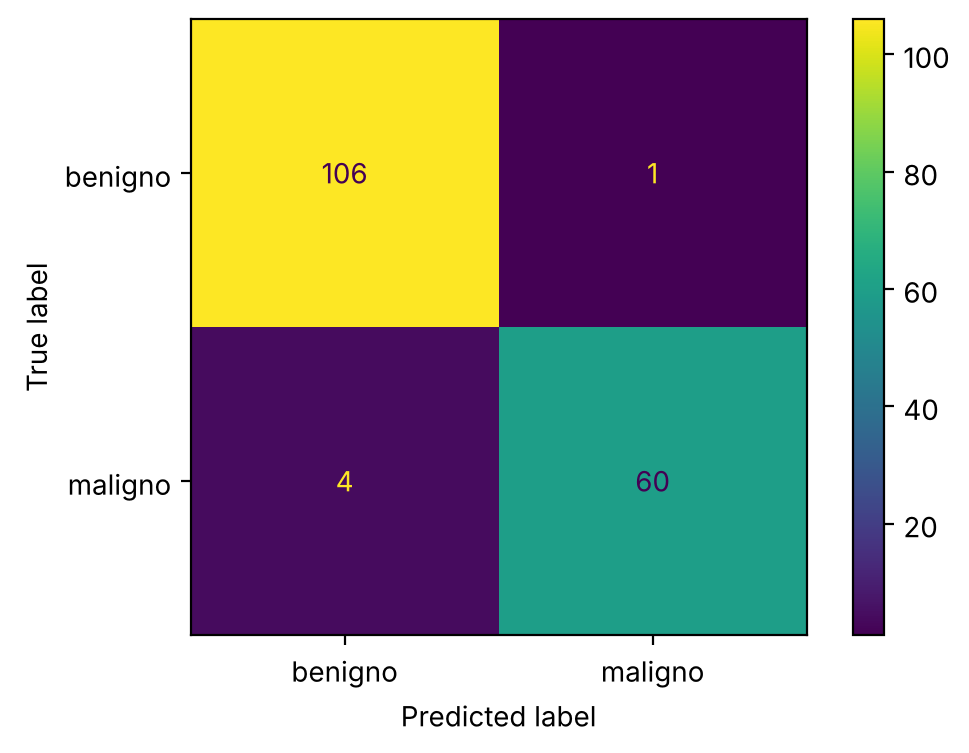

In [41]:
datos = load_breast_cancer()
Xm, ym = datos.data, 1 - datos.target          # 1 = maligno
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=SEMILLA, stratify=ym)
modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xm_tr, ym_tr)
pred = modelo.predict(Xm_te)
ConfusionMatrixDisplay.from_predictions(ym_te, pred, display_labels=["benigno", "maligno"])
plt.show()

| | predijo 0 | predijo 1 |
|---|---|---|
| **real 0** | VN | FP |
| **real 1** | FN | VP |

- **Exactitud** = (VP + VN) / total
- **Precisión** = VP / (VP + FP): de los que dije "maligno", ¿cuántos lo eran?
- **Sensibilidad** (*recall*) = VP / (VP + FN): de los malignos, ¿cuántos encontré?
- **F1** = media armónica de precisión y sensibilidad

### ✏️ Ejercicio 15 · Métricas a mano
Saca `vn, fp, fn, vp` de `confusion_matrix(ym_te, pred).ravel()` y calcula `exactitud`, `precision`, `sensibilidad` y `f1` **con las fórmulas**.

In [42]:
vn, fp, fn, vp = confusion_matrix(ym_te, pred).ravel()
exactitud = (vp + vn) / (vp + vn + fp + fn)
precision = vp / (vp + fp)
sensibilidad = vp / (vp + fn)
f1 = 2 * precision * sensibilidad / (precision + sensibilidad)
print(f"exactitud {exactitud:.3f} · precisión {precision:.3f} · sensibilidad {sensibilidad:.3f} · F1 {f1:.3f}")

exactitud 0.971 · precisión 0.984 · sensibilidad 0.938 · F1 0.960


In [43]:
revisar(lambda: abs(exactitud - accuracy_score(ym_te, pred)) < 1e-9 and abs(precision - precision_score(ym_te, pred)) < 1e-9
        and abs(sensibilidad - recall_score(ym_te, pred)) < 1e-9 and abs(f1 - f1_score(ym_te, pred)) < 1e-9,
        "Tus fórmulas coinciden con scikit-learn.", "Revisa qué celda es VP, FP, FN y VN.")

✅ Tus fórmulas coinciden con scikit-learn.


### El umbral
Por defecto se predice "maligno" si $p \ge 0.5$. En medicina, **no detectar** un maligno (FN) es mucho peor que una falsa alarma (FP). Bajar el umbral sube la sensibilidad a cambio de precisión.

### ✏️ Ejercicio 16
Con `probs = modelo.predict_proba(Xm_te)[:, 1]`, calcula la sensibilidad y la precisión para los umbrales `[0.1, 0.3, 0.5, 0.7, 0.9]`. Guarda en `umbral_seguro` el **mayor** umbral que logra sensibilidad **≥ 0.98**.

In [44]:
probs = modelo.predict_proba(Xm_te)[:, 1]
filas = []
for u in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pu = (probs >= u).astype(int)
    filas.append({"umbral": u, "sensibilidad": recall_score(ym_te, pu), "precisión": precision_score(ym_te, pu)})
tabla = pd.DataFrame(filas)
umbral_seguro = tabla[tabla["sensibilidad"] >= 0.98]["umbral"].max()
print("umbral seguro:", umbral_seguro)
tabla.round(3)

umbral seguro: 0.1


,umbral,sensibilidad,precisión
0,0.1,0.984,0.900
1,0.3,0.969,0.984
2,0.5,0.938,0.984
3,0.7,0.922,1.000
4,0.9,0.797,1.000


In [45]:
revisar(lambda: recall_score(ym_te, (probs >= umbral_seguro).astype(int)) >= 0.98 and umbral_seguro < 0.5, lambda: f"Con umbral {umbral_seguro} encuentras ≥ 98 % de los malignos.", "Recorre los umbrales y quédate con el mayor que cumple.")

✅ Con umbral 0.1 encuentras ≥ 98 % de los malignos.


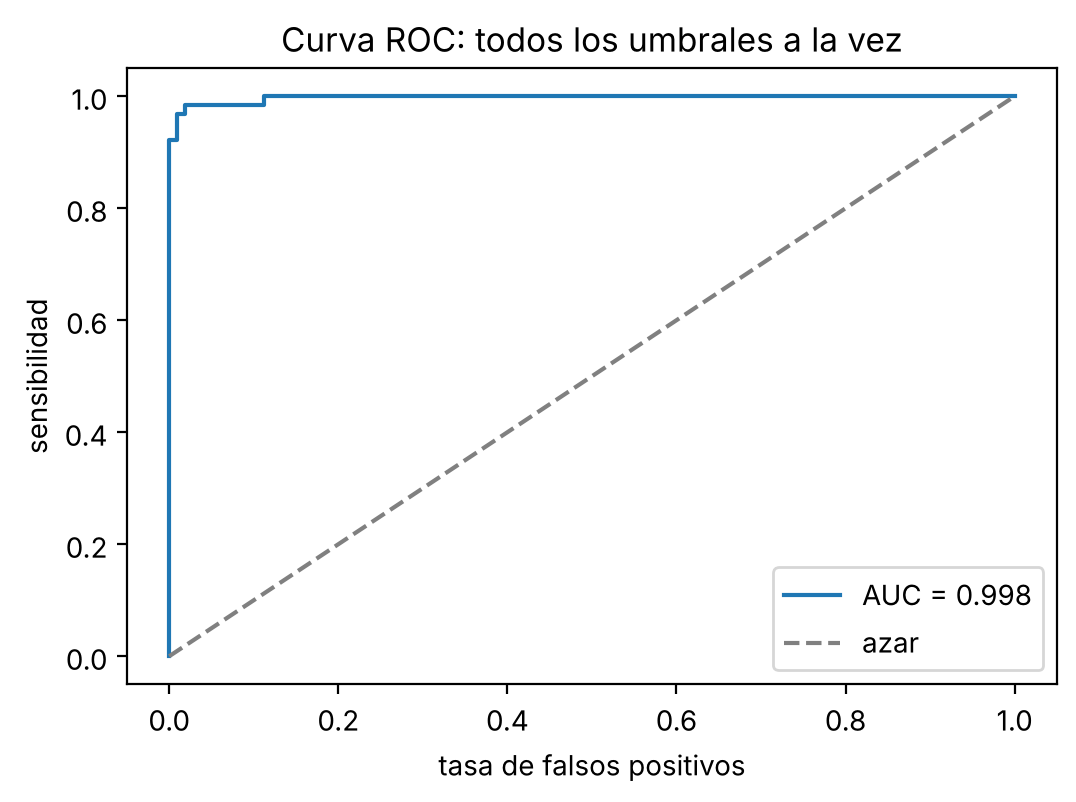

In [46]:
fpr, tpr, _ = roc_curve(ym_te, probs)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(ym_te, probs):.3f}"); plt.plot([0, 1], [0, 1], "--", c="gray", label="azar")
plt.xlabel("tasa de falsos positivos"); plt.ylabel("sensibilidad"); plt.title("Curva ROC: todos los umbrales a la vez")
plt.legend(); plt.show()

### La trampa de la exactitud con clases desbalanceadas
### ✏️ Ejercicio 17
Imagina un problema de fraude donde solo **2 %** son fraudes. Entrena un `DummyClassifier(strategy="most_frequent")` (siempre dice "no es fraude") y guarda su exactitud en `exact_tonto` y su sensibilidad en `sens_tonto`.

In [47]:
rng = np.random.default_rng(SEMILLA)
X_fraude = rng.normal(size=(1000, 3))
y_fraude = (rng.random(1000) < 0.02).astype(int)

In [48]:
tonto = DummyClassifier(strategy="most_frequent").fit(X_fraude, y_fraude)
pt = tonto.predict(X_fraude)
exact_tonto, sens_tonto = accuracy_score(y_fraude, pt), recall_score(y_fraude, pt)
print(f"exactitud {exact_tonto:.1%} · sensibilidad {sens_tonto:.0%}")

exactitud 98.3% · sensibilidad 0%


In [49]:
revisar(lambda: exact_tonto > 0.97 and sens_tonto == 0, "¡98 % de exactitud sin detectar UN solo fraude! Mira siempre la sensibilidad.", 'DummyClassifier(strategy="most_frequent")')

✅ ¡98 % de exactitud sin detectar UN solo fraude! Mira siempre la sensibilidad.


## 11. Comparar modelos: cáncer de mama
### ✏️ Ejercicio 18
Para cada modelo del diccionario, calcula la exactitud media con **validación cruzada de 5 partes** en `Xm_tr, ym_tr` y su **sensibilidad** en prueba. Guarda todo en el DataFrame `comparacion` con columnas `modelo`, `cv` y `sensibilidad_prueba`.

In [50]:
modelos = {
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "kNN (k=7)":           make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "Árbol (prof. 4)":     DecisionTreeClassifier(max_depth=4, random_state=SEMILLA),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=SEMILLA),
    "SVM rbf":             make_pipeline(StandardScaler(), SVC()),
    "Naive Bayes":         GaussianNB(),
}

In [51]:
filas = []
for nombre, m in modelos.items():
    cv = cross_val_score(m, Xm_tr, ym_tr, cv=5).mean()
    sens = recall_score(ym_te, m.fit(Xm_tr, ym_tr).predict(Xm_te))
    filas.append({"modelo": nombre, "cv": cv, "sensibilidad_prueba": sens})
comparacion = pd.DataFrame(filas).sort_values("cv", ascending=False)
comparacion.round(3)

,modelo,cv,sensibilidad_prueba
0,Regresión logística,0.972,0.938
4,SVM rbf,0.972,0.891
1,kNN (k=7),0.965,0.906
3,Random Forest,0.950,0.922
5,Naive Bayes,0.940,0.844
2,Árbol (prof. 4),0.927,0.781


In [52]:
revisar(lambda: len(comparacion) == 6 and comparacion["cv"].min() > 0.85, lambda: f"Mejor por validación cruzada: {comparacion.iloc[0]['modelo']}.", "Un registro por modelo con cv y sensibilidad.")

✅ Mejor por validación cruzada: Regresión logística.


| Algoritmo | Cuándo pensarlo |
|---|---|
| Regresión logística | primer modelo, interpretable, probabilidades |
| kNN | pocos datos, fronteras irregulares (¡escala!) |
| Árbol | reglas que se pueden explicar |
| Random Forest | buen desempeño sin mucho ajuste |
| SVM | dimensión alta, márgenes claros |
| Naive Bayes | texto, muchos datos, rapidez |

## 12. 🏆 Reto final: ¿quién aprueba?

Simulamos **500 alumnos** con 4 variables (horas, asistencia, tareas entregadas y horas de sueño).

1. Separa entrenamiento y prueba (30 %).
2. Prueba **al menos tres** algoritmos y ajusta un hiperparámetro de cada uno con validación cruzada.
3. Elige tu modelo final y reporta su exactitud, precisión y sensibilidad en prueba.
4. **Ana** estudia 6 h, asiste 95 %, entregó 9 tareas y duerme 7 h. ¿Qué probabilidad de aprobar le da tu modelo? Guárdala en `prob_ana_final`.
5. Escribe en una celda de texto: ¿tu modelo tiene más **sesgo** o más **varianza**? ¿Cómo lo sabes?

In [53]:
rng = np.random.default_rng(2026)
n = 500
reto = pd.DataFrame({
    "horas": rng.uniform(0, 10, n).round(1),
    "asistencia": rng.uniform(50, 100, n).round(0),
    "tareas": rng.integers(0, 11, n),
    "sueno": rng.normal(7, 1.2, n).round(1),
})
z = 0.6 * reto["horas"] + 0.06 * reto["asistencia"] + 0.3 * reto["tareas"] - 0.4 * (reto["sueno"] - 7.5) ** 2 - 9
reto["aprobo"] = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
ana_reto = pd.DataFrame({"horas": [6], "asistencia": [95], "tareas": [9], "sueno": [7]})
reto.head()

,horas,asistencia,tareas,sueno,aprobo
0,1.8,94.0,5,8.0,1
1,6.4,63.0,8,5.8,0
2,4.7,95.0,2,5.0,0
3,3.7,65.0,1,6.6,0
4,3.5,53.0,7,7.1,0


In [54]:
Xr, yr = reto.drop(columns="aprobo"), reto["aprobo"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.3, random_state=SEMILLA, stratify=yr)
candidatos = {}
for C in [0.01, 0.1, 1, 10]:
    candidatos[f"logreg C={C}"] = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1000))
for k in [5, 15, 31]:
    candidatos[f"kNN k={k}"] = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
for d in [3, 6, None]:
    candidatos[f"bosque prof={d}"] = RandomForestClassifier(n_estimators=200, max_depth=d, random_state=SEMILLA)
cv = {nombre: cross_val_score(m, Xr_tr, yr_tr, cv=5).mean() for nombre, m in candidatos.items()}
mejor = max(cv, key=cv.get)
final = candidatos[mejor].fit(Xr_tr, yr_tr)
pr = final.predict(Xr_te)
print(pd.Series(cv).sort_values(ascending=False).round(3))
print(f"\nModelo final: {mejor}")
print(f"exactitud {accuracy_score(yr_te, pr):.3f} · precisión {precision_score(yr_te, pr):.3f} · sensibilidad {recall_score(yr_te, pr):.3f}")
print(f"entrenamiento {final.score(Xr_tr, yr_tr):.3f} vs prueba {final.score(Xr_te, yr_te):.3f}")
prob_ana_final = final.predict_proba(ana_reto)[0, 1]
print(f"P(Ana aprueba) = {prob_ana_final:.2f}")

logreg C=0.01       0.797
kNN k=31            0.797
kNN k=15            0.780
bosque prof=3       0.771
bosque prof=None    0.769
logreg C=0.1        0.766
bosque prof=6       0.760
logreg C=1          0.757
logreg C=10         0.757
kNN k=5             0.740
dtype: float64

Modelo final: logreg C=0.01
exactitud 0.767 · precisión 0.767 · sensibilidad 0.687
entrenamiento 0.791 vs prueba 0.767
P(Ana aprueba) = 0.63


In [55]:
revisar(lambda: 0 <= prob_ana_final <= 1, lambda: f"Tu modelo le da a Ana {prob_ana_final:.0%} de probabilidad de aprobar.", "Usa predict_proba(ana_reto)[0, 1] con tu modelo final.")

✅ Tu modelo le da a Ana 63% de probabilidad de aprobar.


✍️ *Escribe aquí tu respuesta sobre sesgo y varianza:*

---
### 🎉 ¡Terminaste el módulo!
Respondiste "¿Ana aprobará?" con seis algoritmos, entendiste qué hace cada uno por dentro y aprendiste a evaluarlos sin engañarte.